In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [50]:
df_bronze = pd.read_csv('history.csv')

In [51]:
df_bronze.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'CustomerFeedback', 'MonthlyIncome'],
      dtype='str')

In [52]:
df_bronze.info()

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   str    
 1   gender            5634 non-null   str    
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   str    
 4   Dependents        5634 non-null   str    
 5   tenure            5634 non-null   str    
 6   PhoneService      5634 non-null   str    
 7   MultipleLines     5634 non-null   str    
 8   InternetService   5634 non-null   str    
 9   OnlineSecurity    5634 non-null   str    
 10  OnlineBackup      5634 non-null   str    
 11  DeviceProtection  5634 non-null   str    
 12  TechSupport       5634 non-null   str    
 13  StreamingTV       5634 non-null   str    
 14  StreamingMovies   5634 non-null   str    
 15  Contract          5634 non-null   str    
 16  PaperlessBilling  5634 non-null   str    
 17  Paymen

## **Dicionário de dados**

- Varíavel 
- Definição
- Tipagem

| Nº | Coluna             | Descrição                                                                                                              | Tipo de dado         |
| -: | ------------------ | ---------------------------------------------------------------------------------------------------------------------- | -------------------- |
|  0 | `customerID`       | Identificador único do cliente                                                                                         | String               |
|  1 | `gender`           | Gênero do cliente (`Male`, `Female`)                                                                                   | Categórico (2 tipos) |
|  2 | `SeniorCitizen`    | Indica se o cliente é idoso                                                                                            | Boolean              |
|  3 | `Partner`          | Indica se o cliente possui parceiro(a), marido ou esposa                                                               | Boolean              |
|  4 | `Dependents`       | Indica se o cliente possui dependentes, como filhos                                                                    | Boolean              |
|  5 | `tenure`           | Tempo de relacionamento do cliente em meses                                                                            | Int                  |
|  6 | `PhoneService`     | Indica se o cliente possui serviço de telefonia. Padronizar `No`, `no`, `Yes` e `yes`                                  | Boolean              |
|  7 | `MultipleLines`    | Indica se o cliente possui mais de uma linha. (`No phone service`,`No`, `Yes`)                                         | Categórico (3 tipos) |
|  8 | `InternetService`  | Tipo de serviço de internet (`DSL`, `No`, `Fiber optic`)                                                               | Categórico (3 tipos) |
|  9 | `OnlineSecurity`   | Indica se o cliente possui serviço de segurança online. (`No internet service`, `No`, `Yes`)                           | Categórico (3 tipos) |
| 10 | `OnlineBackup`     | Indica se o cliente possui serviço de backup online. (`No internet service`, `No`, `Yes`)                              | Categórico (3 tipos) |
| 11 | `DeviceProtection` | Indica se o cliente possui proteção de dispositivos. (`No internet service`, `No`, `Yes`)                              | Categórico (3 tipos) |
| 12 | `TechSupport`      | Indica se o cliente possui suporte técnico. (`No internet service`, `No`, `Yes`)                                       | Categórico (3 tipos) |
| 13 | `StreamingTV`      | Indica se o cliente possui serviço de streaming de TV. (`No internet service`, `No`, `yes`)                            | Categórico (3 tipos) |
| 14 | `StreamingMovies`  | Indica se o cliente possui serviço de streaming de filmes. (`No internet service`, `No`, `yes`)                        | Categórico (3 tipos) |
| 15 | `Contract`         | Tipo de contrato (`One year`, `Month-to-month`, `Two year`)                                                            | Categórico (3 tipos) |
| 16 | `PaperlessBilling` | Indica se a fatura é digital                                                                                           | Boolean              |
| 17 | `PaymentMethod`    | Método de pagamento (`Electronic check`, `Mailed check`, `Bank transfer (automatic)`, `Credit card (automatic)`)       | Categórico (4 tipos) |
| 18 | `MonthlyCharges`   | Valor cobrado mensalmente pelo plano e pelos serviços contratados                                                      | Float                |
| 19 | `TotalCharges`     | Valor total cobrado durante o período de relacionamento, podendo variar devido a descontos, promoções e outros fatores | Float                |
| 20 | `Churn`            | Indica se o cliente cancelou a assinatura                                                                              | Boolean              |
| 21 | `CustomerFeedback` | Feedback do cliente sobre a assinatura, incluindo pontos positivos e negativos                                         | String               |
| 22 | `MonthlyIncome`    | Renda mensal do cliente                                                                                                | Float                |


In [53]:
df_bronze.shape

(5634, 23)

In [54]:
df_bronze.sample(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
374,6893-ODYYE,Male,0,No,No,50,Yes,No,Fiber optic,Yes,...,No,No,One year,Yes,Credit card (automatic),90.10,4549.45,No,"""I have been a loyal customer with this compan...",373
4265,3985-HOYPM,Male,0,No,No,26,Yes,No,No,No internet service,...,No internet service,No internet service,One year,No,Mailed check,19.40,525.55,No,I have been a customer with this company for 2...,749
4702,5887-IKKYO,Male,0,Yes,Yes,58,Yes,Yes,Fiber optic,No,...,No,Yes,Two year,No,Bank transfer (automatic),94.35,5563.65,No,I have been a loyal customer for 58 months now...,5054
5278,3551-HUAZH,Male,1,No,No,1,Yes,Yes,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,74.40,74.40,Yes,I signed up for the fiber optic internet servi...,3074
1575,4307-KTUMW,Male,0,Yes,No,53,Yes,Yes,Fiber optic,Yes,...,No,Yes,Month-to-month,No,Electronic check,93.90,NaN,Yes,I have been a customer with this company for o...,3848
1907,4482-FTFFX,Male,0,No,No,5,Yes,No,DSL,No,...,No,No,Month-to-month,No,Electronic check,56.15,291.45,No,I have been a customer with this DSL internet ...,689
2199,8606-CIQUL,Male,1,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),115.75,8399.15,No,I have been a customer with this company for 6...,2421
4188,4377-VDHYI,Male,0,Yes,Yes,32,Yes,No,Fiber optic,Yes,...,No,Yes,One year,Yes,Electronic check,90.80,3023.85,No,I have been a customer with this company for 3...,6557
2650,4074-SJFFA,Female,0,No,No,1,Yes,No,DSL,No,...,No,Yes,Month-to-month,Yes,Mailed check,54.75,54.75,Yes,I recently signed up for DSL internet service ...,2076
2259,4404-HIBDJ,Female,0,No,No,25,Yes,No,DSL,Yes,...,Yes,No,One year,No,Mailed check,74.30,1863.80,Yes,I have been a customer with this company for 2...,2999


### Verificação das colunas em geral: quantos valores únicos, nulos e duplicados

In [55]:
for coluna in df_bronze.columns:
    print(f'Coluna: {coluna}')
    print(f"Quantidade de valores: {len(df_bronze[coluna])}")
    print(f"Valores únicos: {df_bronze[coluna].nunique()}")
    print(f"Valores nulos: {df_bronze[coluna].isnull().sum()}")
    print(f"Valores duplicados: {df_bronze[coluna].duplicated().sum()}")
    print(f"Tipo dos dados: {df_bronze[coluna].dtypes}")
    print('-------------------------')
    
print("Linhas inteiras duplicadas:", df_bronze.duplicated().sum())


Coluna: customerID
Quantidade de valores: 5634
Valores únicos: 5634
Valores nulos: 0
Valores duplicados: 0
Tipo dos dados: str
-------------------------
Coluna: gender
Quantidade de valores: 5634
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5632
Tipo dos dados: str
-------------------------
Coluna: SeniorCitizen
Quantidade de valores: 5634
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5632
Tipo dos dados: int64
-------------------------
Coluna: Partner
Quantidade de valores: 5634
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5632
Tipo dos dados: str
-------------------------
Coluna: Dependents
Quantidade de valores: 5634
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5632
Tipo dos dados: str
-------------------------
Coluna: tenure
Quantidade de valores: 5634
Valores únicos: 74
Valores nulos: 0
Valores duplicados: 5560
Tipo dos dados: str
-------------------------
Coluna: PhoneService
Quantidade de valores: 5634
Valores únicos: 4
Valores nulos: 0
Val

### Remoção de nulos e duplicatas e tratamento para a transformação do tipo da coluna(PhoneService, MultipleLines, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, TotalCharges)

Padronizar ```No```, ```no```, ```Yes```, ```yes```: **PhoneService**

Verificar **tenure**: Valores estão como ```unknown```, o que impossibilita transformar em int e realizar calculos

Verificar valores nulos em **TotalCharges**.

In [56]:
df_silver = df_bronze.copy()

In [57]:
# PhoneService
df_silver["PhoneService"] = df_silver["PhoneService"].replace({"no": "No", "yes": "Yes"}) # Transforma os no e yes em No e Yes
df_silver["PhoneService"].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [58]:
# Tenure
# Calculamos com base no total pago e no valor mensal, assim descobriremos a quatidade de meses
# Se o valor total ou de meses for nulo, excluiremos a linha.

# Converte textos inválidos (como 'unknown') da própria coluna tenure para nulos reais
df_silver["tenure"] = pd.to_numeric(df_silver["tenure"], errors='coerce')

# Calcula os meses (Total / Mensal) e arredonda com o método nativo do Pandas
calculo_tenure = (df_silver["TotalCharges"] / df_silver["MonthlyCharges"]).round()

# Preenche os valores nulos do tenure com o resultado calculado
df_silver["tenure"] = df_silver["tenure"].fillna(calculo_tenure)

# Converte o tenure final para o tipo inteiro otimizado que você escolheu
df_silver["tenure"] = df_silver["tenure"].clip(upper=72).astype("Int16") # Definido limite de meses até 72 e transformação dos dados

# REGRA DE EXCLUSÃO: Se o tenure continuou nulo após o cálculo, remove a linha
df_silver = df_silver.dropna(subset=["tenure"])


Foi removido uma linha pelo fato de que o tenure era nulo e o total pago também, logo não tinha como calcular nem um, nem o outro.

In [59]:
indice_removido = df_bronze.index.difference(df_silver.index)
df_bronze.loc[indice_removido]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
1097,9651-GTSAQ,Female,0,Yes,No,unknown,Yes,No,Fiber optic,Yes,...,Yes,Yes,One year,Yes,Bank transfer (automatic),106.1,NaN,Yes,I have been a customer with this company for o...,4702


In [60]:
print("Bronze:", len(df_bronze), "| Silver:", len(df_silver), "| Removidas:", len(df_bronze) - len(df_silver))

Bronze: 5634 | Silver: 5633 | Removidas: 1


In [61]:
df_silver.shape

(5633, 23)

In [62]:
# TotalCharges
# Transforma os valores nulos em valores aproximados com base no tenure(número de meses) * MonthlyCharges
df_silver["TotalCharges"] = df_silver["TotalCharges"].fillna(df_silver["tenure"] * df_silver["MonthlyCharges"])
df_silver["TotalCharges"].isnull().sum()


np.int64(0)

In [63]:
# Conferindo se há advsersidades
for coluna in df_silver.columns:
    print(f'Coluna: {coluna}')
    print(f"Quantidade de valores: {len(df_silver[coluna])}")
    print(f"Valores únicos: {df_silver[coluna].nunique()}")
    print(f"Valores nulos: {df_silver[coluna].isnull().sum()}")
    print(f"Valores duplicados: {df_silver[coluna].duplicated().sum()}")
    print(f"Tipo dos dados: {df_silver[coluna].dtypes}")
    print('-------------------------')

Coluna: customerID
Quantidade de valores: 5633
Valores únicos: 5633
Valores nulos: 0
Valores duplicados: 0
Tipo dos dados: str
-------------------------
Coluna: gender
Quantidade de valores: 5633
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5631
Tipo dos dados: str
-------------------------
Coluna: SeniorCitizen
Quantidade de valores: 5633
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5631
Tipo dos dados: int64
-------------------------
Coluna: Partner
Quantidade de valores: 5633
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5631
Tipo dos dados: str
-------------------------
Coluna: Dependents
Quantidade de valores: 5633
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5631
Tipo dos dados: str
-------------------------
Coluna: tenure
Quantidade de valores: 5633
Valores únicos: 73
Valores nulos: 0
Valores duplicados: 5560
Tipo dos dados: Int16
-------------------------
Coluna: PhoneService
Quantidade de valores: 5633
Valores únicos: 2
Valores nulos: 0
V

### Tratamento dos dados de cada coluna

In [64]:
# Colunas para string
colunas_sring = ["customerID", "CustomerFeedback"]
for coluna in colunas_sring:
    df_silver[coluna] = df_silver[coluna].astype('string') # Transforma de str para string


# Colunas para categórico
colunas_categorico = ["gender", "InternetService", "Contract", "PaymentMethod", "MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
for coluna in colunas_categorico:
    df_silver[coluna] = df_silver[coluna].astype('category') # Transforma de str para categorico
    

# Colunas para boolean
colunas_boolean = ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
mapeamento_booleano = {
    'Yes': True, 'No': False,
    1: True, 0: False,
    '1': True, '0': False
}
for coluna in colunas_boolean:
    df_silver[coluna] = df_silver[coluna].replace(mapeamento_booleano).astype('boolean')


# Para int
df_silver["tenure"] = df_silver["tenure"].astype("Int16")


# Para float
colunas_float = ["MonthlyCharges", "TotalCharges", "MonthlyIncome"]
for coluna in colunas_float:
    df_silver[coluna] = df_silver[coluna].astype('float') # Transforma de str para categorico
    


### Verificando se os valores foram tratados:

In [65]:
# Conferindo se há advsersidades
for coluna in df_silver.columns:
    print(f'Coluna: {coluna}')
    print(f"Quantidade de valores: {len(df_silver[coluna])}")
    print(f"Valores únicos: {df_silver[coluna].nunique()}")
    print(f"Valores nulos: {df_silver[coluna].isnull().sum()}")
    print(f"Valores duplicados: {df_silver[coluna].duplicated().sum()}")
    print(f"Tipo dos dados: {df_silver[coluna].dtypes}")
    if df_silver[coluna].dtypes == 'boolean' or df_silver[coluna].dtypes == 'category':
        print(10*"-")
        print(f"Valores na coluna: {df_silver[coluna].value_counts().to_string()}")
    print(50*'-')

Coluna: customerID
Quantidade de valores: 5633
Valores únicos: 5633
Valores nulos: 0
Valores duplicados: 0
Tipo dos dados: string
--------------------------------------------------
Coluna: gender
Quantidade de valores: 5633
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5631
Tipo dos dados: category
----------
Valores na coluna: gender
Male      2835
Female    2798
--------------------------------------------------
Coluna: SeniorCitizen
Quantidade de valores: 5633
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5631
Tipo dos dados: boolean
----------
Valores na coluna: SeniorCitizen
False    4705
True      928
--------------------------------------------------
Coluna: Partner
Quantidade de valores: 5633
Valores únicos: 2
Valores nulos: 0
Valores duplicados: 5631
Tipo dos dados: boolean
----------
Valores na coluna: Partner
False    2907
True     2726
--------------------------------------------------
Coluna: Dependents
Quantidade de valores: 5633
Valores únicos: 2
Valore

# Análise de Churn

## Análises

- [X] **Tabela de cancelamentos:** criar uma tabela apenas com os clientes que cancelaram.
- [X] **Visão geral:** gráfico de pizza com o total de clientes e a porcentagem de cancelamentos, para avaliar quantas pessoas cancelaram no total.
- [X] **Tipo de contrato:** analisar o churn por contrato (mensal, anual e dois anos) e a receita perdida, com um gráfico separado.
- [X] **Tempo de relacionamento:** cancelamento por `tenure`, com gráfico de relação temporal.
- [X] **Serviço de internet:** cancelamento por tipo de internet (fibra óptica, DSL e sem internet).
- [X] **Forma de pagamento:** cancelamento por tipo de pagamento.
- [X] **Faixa salarial:** cancelamento por faixa de renda (`MonthlyIncome`).
- [X] **Fatura mensal:** cancelamento por valor da fatura mensal (`MonthlyCharges`).

## Bônus

- [ ] **Feedback:** analisar o `CustomerFeedback` e gerar uma matriz de risco.
- [ ] **Camada gold:** analisar as tabelas gold por tipo de contrato, tipo de serviço e tipo de pagamento, com base no churn.

## Entrega final

- [X] Montar o modelo dos gráficos finais, com algumas soluções propostas.

### Todos os valores dentro do dataframe foram tratados, o que nos leva para a camada gold

#### Gerando df apenas com os churns

In [69]:
df_churn = df_silver[df_silver['Churn']]

In [70]:
df_churn.sample(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
3690,9445-SZLCH,Female,False,True,True,36,True,Yes,Fiber optic,No,...,Yes,No,Month-to-month,True,Bank transfer (automatic),97.35,3457.90,True,I have been a customer with this company for 3...,6666.0
4745,1043-YCUTE,Male,False,True,False,56,True,Yes,No,No internet service,...,No internet service,No internet service,Two year,True,Credit card (automatic),25.15,1327.15,True,I have been a customer with this company for 5...,9546.0
3426,8779-QRDMV,Male,True,False,False,1,False,No phone service,DSL,No,...,No,Yes,Month-to-month,True,Electronic check,39.65,39.65,True,"""I recently signed up for DSL internet service...",8396.0
904,8580-AECUZ,Male,True,False,False,1,True,No,Fiber optic,No,...,Yes,No,Month-to-month,True,Electronic check,79.10,79.10,True,I recently switched to this internet service p...,1839.0
4718,6210-KBBPI,Male,True,False,False,9,True,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,True,Credit card (automatic),99.45,919.40,True,I recently canceled my service after being a c...,1671.0
1395,3550-SAHFP,Female,False,False,False,33,True,Yes,Fiber optic,No,...,No,Yes,Month-to-month,True,Electronic check,83.35,2757.85,True,I recently decided to cancel my service after ...,5326.0
3239,1208-DNHLN,Male,False,True,True,23,True,Yes,DSL,No,...,No,No,One year,True,Credit card (automatic),48.35,1067.15,True,I have been a customer with this company for 2...,6986.0
2575,2514-GINMM,Male,False,False,False,1,True,No,Fiber optic,No,...,Yes,No,Month-to-month,True,Electronic check,79.50,79.50,True,I recently signed up for fiber optic internet ...,3276.0
3597,0280-XJGEX,Male,False,False,False,49,True,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,True,Bank transfer (automatic),103.70,5036.30,True,I recently decided to switch internet provider...,4473.0
3808,5077-DXTCG,Female,False,False,False,1,True,No,DSL,No,...,No,No,Month-to-month,True,Electronic check,45.30,45.30,True,I recently signed up for DSL internet service ...,3089.0


### Preparando variaveis para o gráfico

In [71]:
VERMELHO, AZUL, CINZA = "#a50027", "#4c78a8", "#8c8c8c"
media_geral = df_churn.shape[0] / len(df_silver) * 100         # churn geral (26.7%)

usd = lambda v: f"US$ {v:,.0f}".replace(",", ".")
fmt_usd = FuncFormatter(lambda x, _: usd(x))

# versão numérica auxiliar (Churn 0/1 e tenure inteiro) para médias e linhas
base = df_silver.assign(Churn=df_silver["Churn"].astype(float), tenure=df_silver["tenure"].astype(int))

## 1. Visão geral: clientes, faturamento mensal e parcela média

**Esquerda (pizza):** divide a base entre clientes que cancelaram e que ficaram. É o ponto de partida da análise: 26.7% dos clientes cancelaram (1503 de 5633).

**Centro (faturamento mensal):** compara o faturamento mensal de quem ficou, US$ 251767, com o que foi perdido com quem cancelou, US$ 112137. Os dois valores somam os US$ 363904 que a base faturava por mês antes dos cancelamentos.

**Direita (parcela média):** compara a parcela mensal média de quem ficou (US$ 60.96) e de quem cancelou (US$ 74.61). Quem cancelou pagava mais, por isso a perda de receita pesa mais que a perda de clientes.

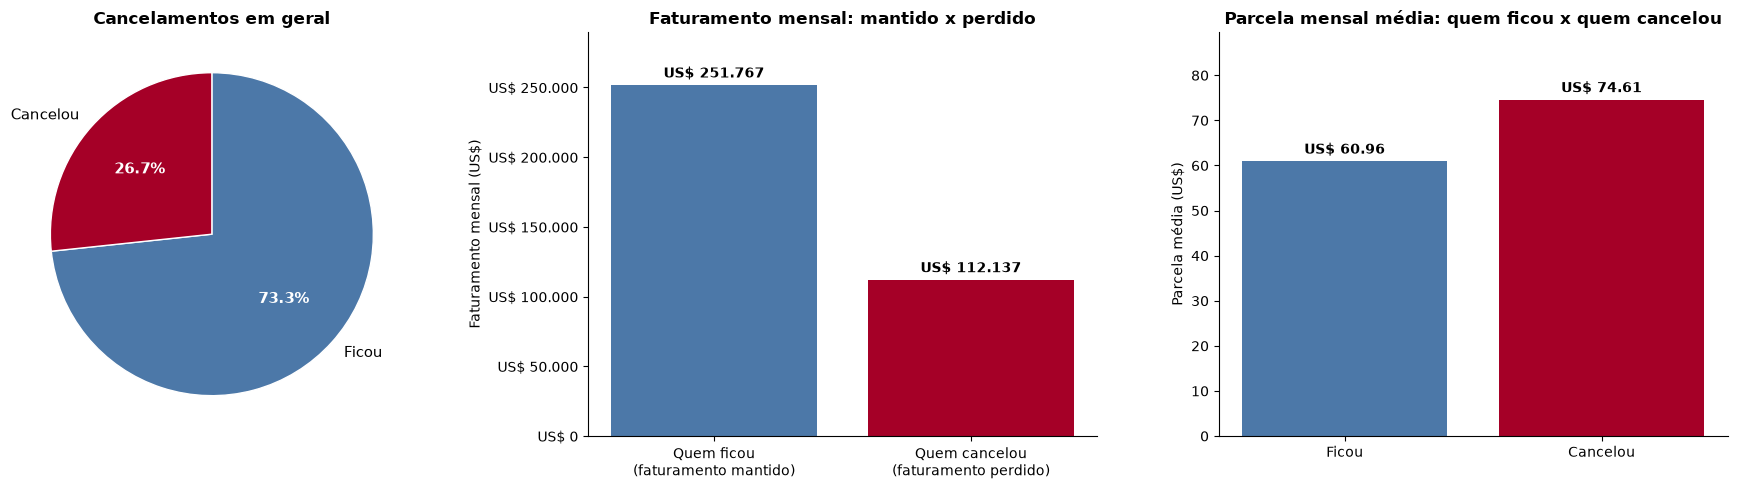

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Pizza: cancelou x ficou
_, _, porcentagens = axes[0].pie(
    [len(df_silver) - len(df_churn), len(df_churn)],
    labels=["Ficou", "Cancelou"], colors=[AZUL, VERMELHO],
    autopct=lambda p: f"{p:.1f}%", startangle=90, counterclock=False,
    wedgeprops=dict(edgecolor="white"), textprops=dict(fontsize=11),
)
for texto in porcentagens:
    texto.set_color("white")
    texto.set_fontweight("bold")
axes[0].set_title("Cancelamentos em geral", fontweight="bold")

# Barras: faturamento mensal mantido (ficou) x perdido (cancelou)
faturamento = [base.loc[base["Churn"] == 0, "MonthlyCharges"].sum(),
               base.loc[base["Churn"] == 1, "MonthlyCharges"].sum()]
barras = axes[1].bar(["Quem ficou\n(faturamento mantido)", "Quem cancelou\n(faturamento perdido)"],
                     faturamento, color=[AZUL, VERMELHO])
axes[1].bar_label(barras, labels=[usd(v) for v in faturamento], padding=3, fontweight="bold")
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_ylim(0, max(faturamento) * 1.15)
axes[1].set_title("Faturamento mensal: mantido x perdido", fontweight="bold")
axes[1].set_ylabel("Faturamento mensal (US$)")
axes[1].spines[["top", "right"]].set_visible(False)

# Barras: parcela mensal média
medias = [base.loc[base["Churn"] == 0, "MonthlyCharges"].mean(),
          base.loc[base["Churn"] == 1, "MonthlyCharges"].mean()]
barras = axes[2].bar(["Ficou", "Cancelou"], medias, color=[AZUL, VERMELHO])
axes[2].bar_label(barras, labels=[f"US$ {m:.2f}" for m in medias], padding=3, fontweight="bold")
axes[2].set_ylim(0, max(medias) * 1.2)
axes[2].set_title("Parcela mensal média: quem ficou x quem cancelou", fontweight="bold")
axes[2].set_ylabel("Parcela média (US$)")
axes[2].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 2. Tipo de contrato

**Esquerda:** entre os clientes que cancelaram, qual a proporção de cada tipo de contrato (as barras somam 100%). 88.0% dos cancelados tinham contrato mensal, 9.1% anual e 2.9% de dois anos.

**Direita:** quanto de fatura mensal a empresa deixou de receber com esses cancelamentos, por tipo de contrato. São US$ 112137 por mês no total, e o contrato mensal concentra US$ 96852 (86.4%).

Os dois juntos mostram que o contrato mensal é o maior problema, tanto em quantidade de clientes quanto em receita.

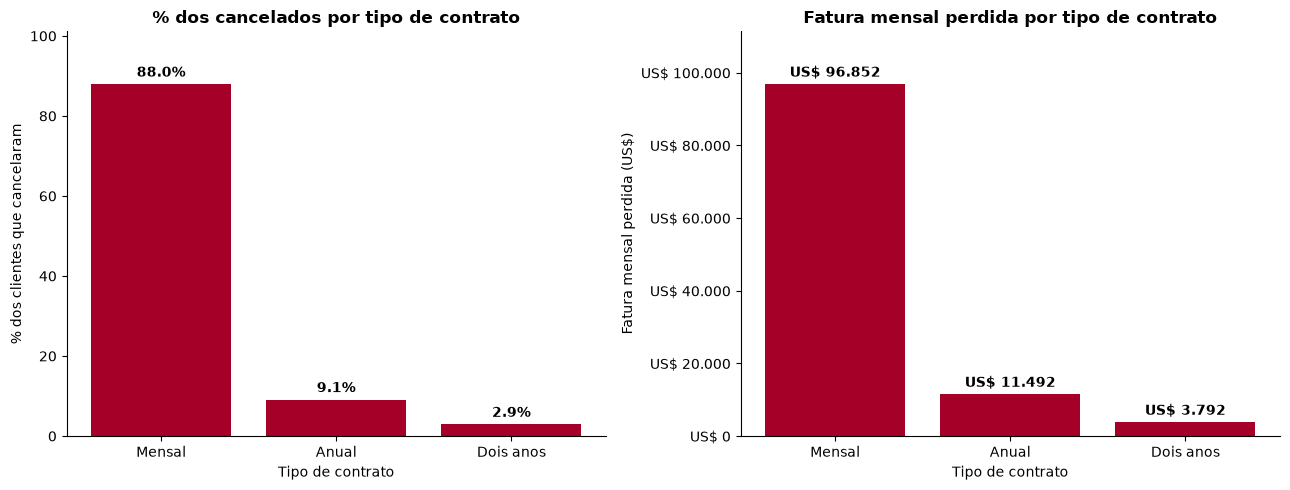

In [73]:
ordem = ["Month-to-month", "One year", "Two year"]
nomes = ["Mensal", "Anual", "Dois anos"]

contagem = df_churn["Contract"].value_counts().reindex(ordem)
porcentagem = contagem / contagem.sum() * 100
perda = df_churn.groupby("Contract", observed=True)["MonthlyCharges"].sum().reindex(ordem)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

barras = axes[0].bar(nomes, porcentagem, color=VERMELHO)
axes[0].bar_label(barras, labels=[f"{p:.1f}%" for p in porcentagem], padding=3, fontweight="bold")
axes[0].set_title("% dos cancelados por tipo de contrato", fontweight="bold")
axes[0].set_ylabel("% dos clientes que cancelaram")
axes[0].set_ylim(0, porcentagem.max() * 1.15)

barras = axes[1].bar(nomes, perda, color=VERMELHO)
axes[1].bar_label(barras, labels=[usd(v) for v in perda], padding=3, fontweight="bold")
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_title("Fatura mensal perdida por tipo de contrato", fontweight="bold")
axes[1].set_ylabel("Fatura mensal perdida (US$)")
axes[1].set_ylim(0, perda.max() * 1.15)

for ax in axes:
    ax.set_xlabel("Tipo de contrato")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 3. Serviço de internet

**Esquerda:** entre os clientes que cancelaram, a proporção de cada tipo de internet: 69.3% tinham fibra óptica, 24.8% DSL e 5.9% não tinham internet.

**Direita:** a fatura mensal perdida por tipo de internet. A fibra óptica sozinha responde por US$ 92063 dos US$ 112137 perdidos (82.1%), enquanto DSL perdeu US$ 18261 e quem não tinha internet, US$ 1813.

Atenção: a fibra também é o serviço com mais clientes (44.0% da base) e tem parcelas mais altas, o que amplia o peso dela na receita perdida.

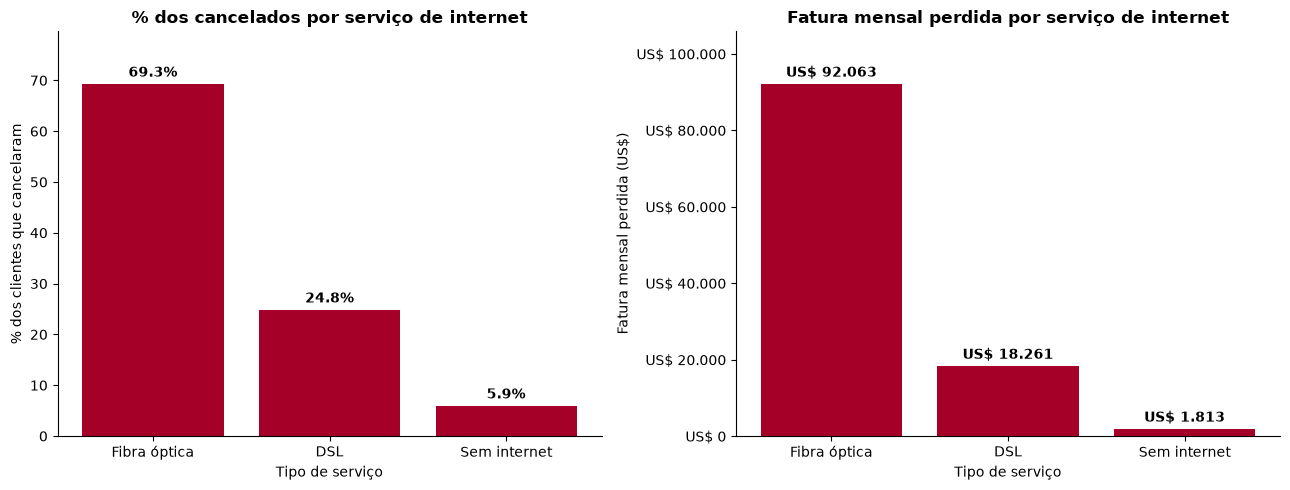

In [74]:
ordem = ["Fiber optic", "DSL", "No"]
nomes = ["Fibra óptica", "DSL", "Sem internet"]

contagem = df_churn["InternetService"].value_counts().reindex(ordem)
porcentagem = contagem / contagem.sum() * 100
perda = df_churn.groupby("InternetService", observed=True)["MonthlyCharges"].sum().reindex(ordem)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

barras = axes[0].bar(nomes, porcentagem, color=VERMELHO)
axes[0].bar_label(barras, labels=[f"{p:.1f}%" for p in porcentagem], padding=3, fontweight="bold")
axes[0].set_title("% dos cancelados por serviço de internet", fontweight="bold")
axes[0].set_ylabel("% dos clientes que cancelaram")
axes[0].set_ylim(0, porcentagem.max() * 1.15)

barras = axes[1].bar(nomes, perda, color=VERMELHO)
axes[1].bar_label(barras, labels=[usd(v) for v in perda], padding=3, fontweight="bold")
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_title("Fatura mensal perdida por serviço de internet", fontweight="bold")
axes[1].set_ylabel("Fatura mensal perdida (US$)")
axes[1].set_ylim(0, perda.max() * 1.15)

for ax in axes:
    ax.set_xlabel("Tipo de serviço")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 4. Forma de pagamento

**Esquerda:** entre os clientes que cancelaram, a proporção de cada forma de pagamento. O cheque eletrônico lidera com 56.7%, seguido de cheque postado (16.6%), transferência bancária (14.0%) e cartão de crédito (12.8%).

**Direita:** a fatura mensal perdida por forma de pagamento. O cheque eletrônico perdeu US$ 67442, mais da metade do total, e as outras três formas ficam entre US$ 13682 e US$ 16503.

Os pagamentos automáticos (transferência e cartão) concentram menos cancelamentos.

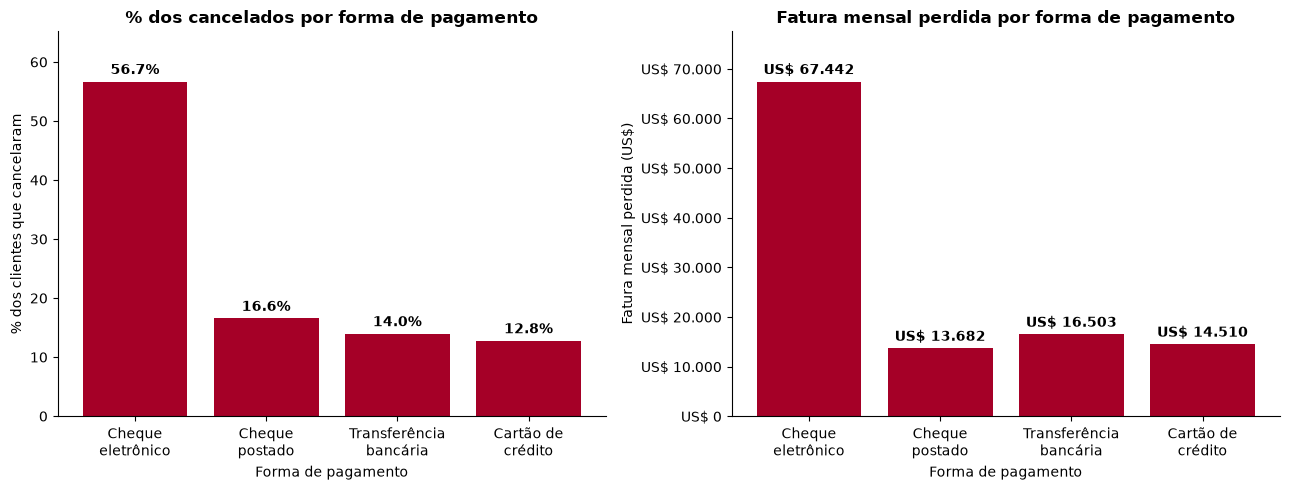

In [75]:
ordem = ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"]
nomes = ["Cheque\neletrônico", "Cheque\npostado", "Transferência\nbancária", "Cartão de\ncrédito"]

contagem = df_churn["PaymentMethod"].value_counts().reindex(ordem)
porcentagem = contagem / contagem.sum() * 100
perda = df_churn.groupby("PaymentMethod", observed=True)["MonthlyCharges"].sum().reindex(ordem)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

barras = axes[0].bar(nomes, porcentagem, color=VERMELHO)
axes[0].bar_label(barras, labels=[f"{p:.1f}%" for p in porcentagem], padding=3, fontweight="bold")
axes[0].set_title("% dos cancelados por forma de pagamento", fontweight="bold")
axes[0].set_ylabel("% dos clientes que cancelaram")
axes[0].set_ylim(0, porcentagem.max() * 1.15)

barras = axes[1].bar(nomes, perda, color=VERMELHO)
axes[1].bar_label(barras, labels=[usd(v) for v in perda], padding=3, fontweight="bold")
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_title("Fatura mensal perdida por forma de pagamento", fontweight="bold")
axes[1].set_ylabel("Fatura mensal perdida (US$)")
axes[1].set_ylim(0, perda.max() * 1.15)

for ax in axes:
    ax.set_xlabel("Forma de pagamento")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 5. Tempo de relacionamento

**Esquerda (linha):** a taxa de churn em cada mês de relacionamento, ou seja, entre os clientes com aquele tempo de casa, quantos cancelaram. Começa acima de 60% no primeiro mês (61.6%) e cai com o tempo, chegando a 9.5% entre 49 e 72 meses. A linha tracejada é a média geral (26.7%). Nos meses finais a linha oscila mais porque há poucos clientes em cada mês.

**Direita (duas linhas):** a parcela mensal média por faixa de 6 meses de relacionamento, separando quem ficou e quem cancelou. Quem cancelou paga mais em todas as faixas, de US$ 63.5 contra US$ 44.2 nos primeiros 6 meses até US$ 98.5 contra US$ 74.6 nos últimos 6 (nas faixas finais há poucos cancelados).

Juntos mostram que o risco está no começo da relação, principalmente entre clientes de parcela mais alta.

C:\Users\Lapa\AppData\Local\Temp\ipykernel_5708\2819743448.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(frameon=False)


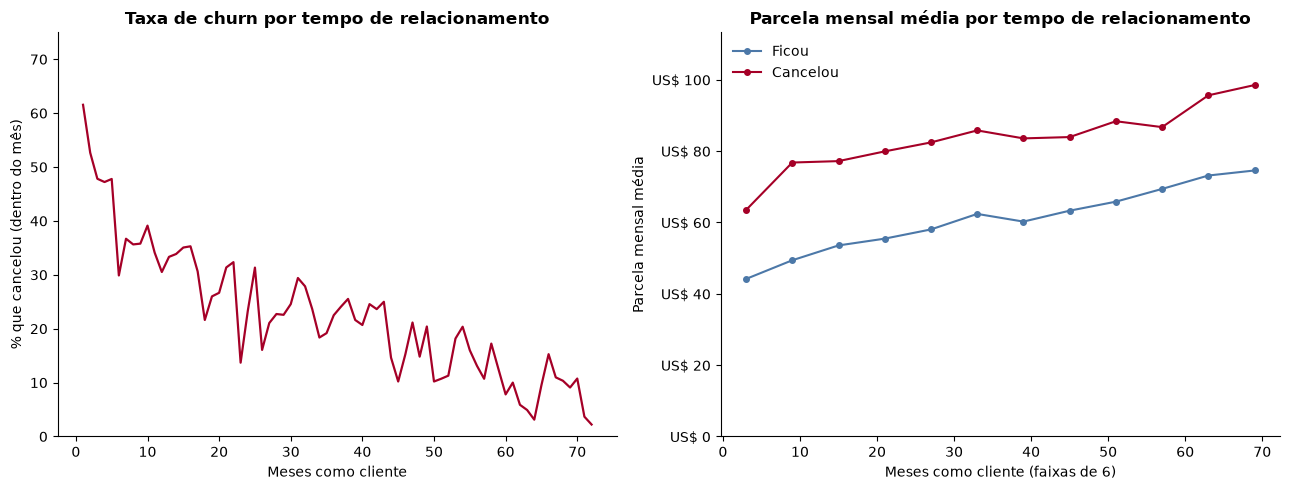

In [80]:
# taxa de churn em cada mês de relacionamento
taxa_mes = base[base["tenure"] >= 1].groupby("tenure")["Churn"].mean() * 100

# parcela média por faixa de 6 meses, separando ficou (0) e cancelou (1)
faixa = pd.cut(base["tenure"], bins=np.arange(0, 73, 6), include_lowest=True)
parcela = base.groupby([faixa, "Churn"], observed=True)["MonthlyCharges"].mean().unstack()
meio_faixa = [intervalo.mid for intervalo in parcela.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(taxa_mes.index, taxa_mes.values, color=VERMELHO, linewidth=1.6)
axes[0].set_title("Taxa de churn por tempo de relacionamento", fontweight="bold")
axes[0].set_xlabel("Meses como cliente")
axes[0].set_ylabel("% que cancelou (dentro do mês)")
axes[0].set_ylim(0, 75)
axes[0].legend(frameon=False)

axes[1].plot(meio_faixa, parcela[0.0], color=AZUL, marker="o", markersize=4, label="Ficou")
axes[1].plot(meio_faixa, parcela[1.0], color=VERMELHO, marker="o", markersize=4, label="Cancelou")
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_title("Parcela mensal média por tempo de relacionamento", fontweight="bold")
axes[1].set_xlabel("Meses como cliente (faixas de 6)")
axes[1].set_ylabel("Parcela mensal média")
axes[1].set_ylim(0, parcela.max().max() * 1.15)
axes[1].legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 6. Preço da parcela e renda

**Esquerda:** a taxa de churn por faixa de preço da parcela mensal. A relação não é linear: até US$ 30 cancela 9.7%, de 30 a 50 cancela 31.2%, de 50 a 70 cancela 20.5%, de 70 a 90 cancela 37.7% e acima de 90 cancela 33.7%. A faixa de 70 a 90 é a de maior risco. A linha tracejada é a média geral (26.7%).

**Direita:** a renda mensal média de quem ficou (US$ 5082) e de quem cancelou (US$ 5168). A diferença é muito pequena, o que indica que a renda não explica o cancelamento. A coluna entra na análise para mostrar justamente isso.

C:\Users\Lapa\AppData\Local\Temp\ipykernel_5708\4075767633.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(frameon=False)


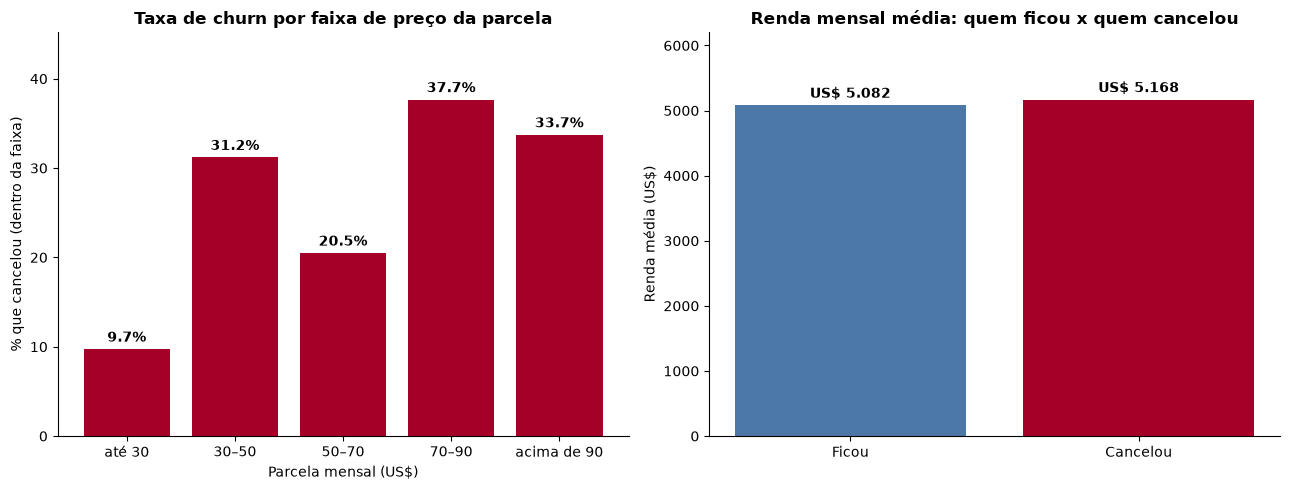

In [81]:
# taxa de churn por faixa de preço da parcela
faixa_preco = pd.cut(base["MonthlyCharges"], [0, 30, 50, 70, 90, 200],
                     labels=["até 30", "30–50", "50–70", "70–90", "acima de 90"])
taxa_preco = base.groupby(faixa_preco, observed=True)["Churn"].mean() * 100

# renda mensal média de quem ficou e de quem cancelou
renda = [base.loc[base["Churn"] == 0, "MonthlyIncome"].mean(),
         base.loc[base["Churn"] == 1, "MonthlyIncome"].mean()]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

barras = axes[0].bar(taxa_preco.index.astype(str), taxa_preco.values, color=VERMELHO)
axes[0].bar_label(barras, labels=[f"{v:.1f}%" for v in taxa_preco.values], padding=3, fontweight="bold")
axes[0].set_title("Taxa de churn por faixa de preço da parcela", fontweight="bold")
axes[0].set_xlabel("Parcela mensal (US$)")
axes[0].set_ylabel("% que cancelou (dentro da faixa)")
axes[0].set_ylim(0, taxa_preco.max() * 1.2)
axes[0].legend(frameon=False)

barras = axes[1].bar(["Ficou", "Cancelou"], renda, color=[AZUL, VERMELHO])
axes[1].bar_label(barras, labels=[usd(v) for v in renda], padding=3, fontweight="bold")
axes[1].set_title("Renda mensal média: quem ficou x quem cancelou", fontweight="bold")
axes[1].set_ylabel("Renda média (US$)")
axes[1].set_ylim(0, max(renda) * 1.2)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 7. Gráfico final: matriz de combinações e ranking das 8 mais críticas

Une os dois gráficos finais em uma só figura, mostrando os três fatores ao mesmo tempo: tipo de contrato, serviço de internet e forma de pagamento.

**Esquerda (matriz):** cada célula é uma combinação dos três fatores. Mostra a taxa de churn (% dos clientes da combinação que cancelaram) e o número de clientes (`n`). Quanto mais escuro o vermelho, maior o churn. Células cinza têm menos de 30 clientes e não entram na leitura. As 8 células com borda preta e numeradas (#1 a #8) são as combinações com maior churn entre as que têm pelo menos 100 clientes.

**Direita (ranking):** as mesmas 8 combinações em barras horizontais, de #1 (no topo) a #8, com a taxa de churn e o `n` ao lado de cada barra. A linha tracejada é a média geral (26.7%).

O pior cenário é contrato mensal, fibra óptica e cheque eletrônico, com 59.9% de churn em 1038 clientes. Sete das oito combinações do ranking são de contrato mensal. Todas as combinações de contrato de dois anos com dados suficientes ficam abaixo de 12%. Os 8 grupos do ranking reúnem 47.7% dos clientes, mas 84% de todos os cancelamentos.

Para mudar o recorte, altere `MIN_CLIENTES` (quantidade mínima de clientes) e `TOP` (quantas combinações entram no ranking).

C:\Users\Lapa\AppData\Local\Temp\ipykernel_5708\3337664508.py:93: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(frameon=False, loc="lower right")


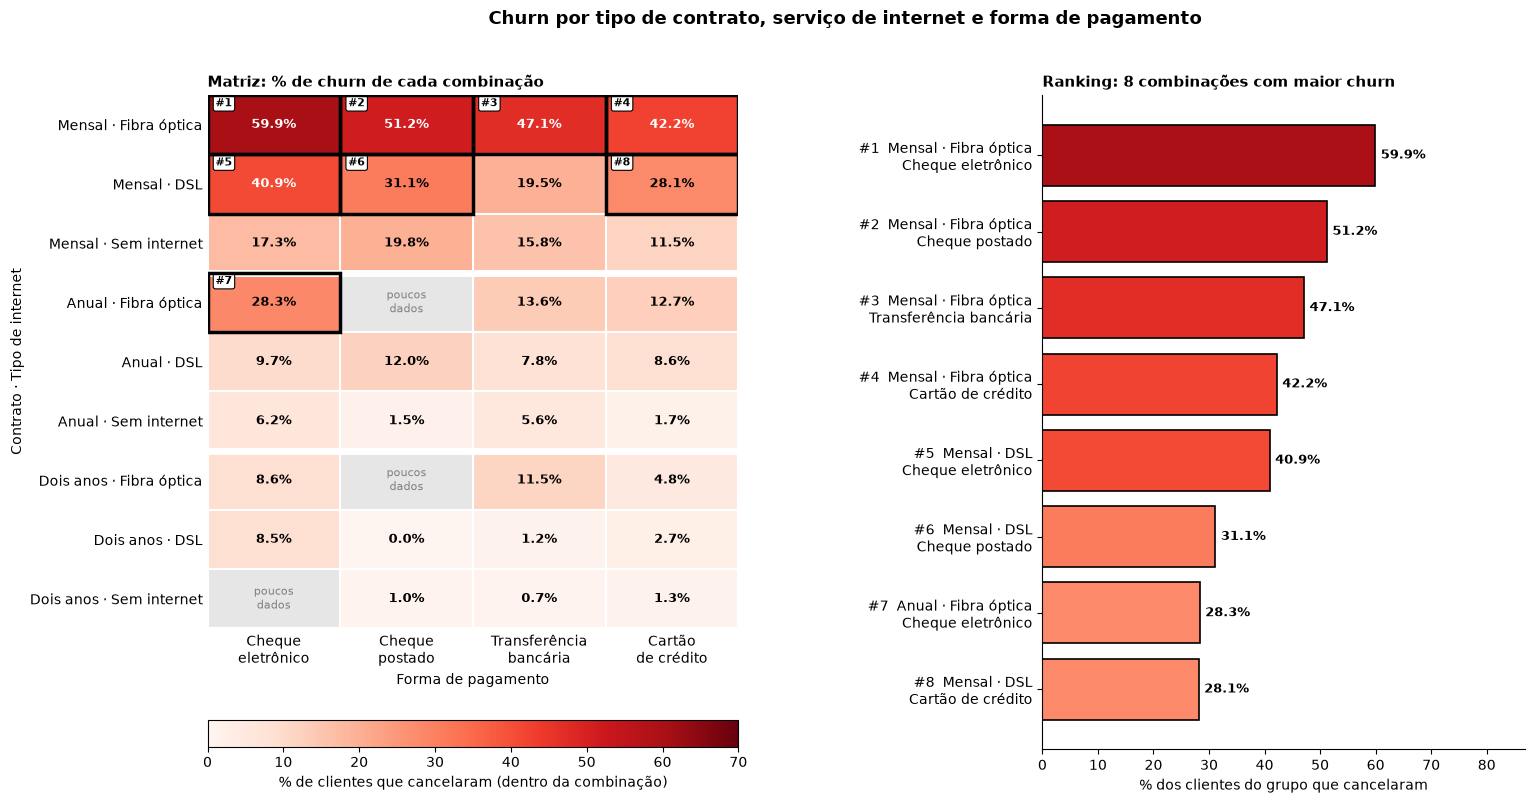

In [85]:
CINZA = "#8c8c8c"
base = df_silver.assign(Churn=df_silver["Churn"].astype(float), tenure=df_silver["tenure"].astype(int))
media_geral = base["Churn"].mean() * 100     # churn geral (26.7%)

contratos = ["Month-to-month", "One year", "Two year"]
internets = ["Fiber optic", "DSL", "No"]
pagamentos = ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"]

nome_contrato = {"Month-to-month": "Mensal", "One year": "Anual", "Two year": "Dois anos"}
nome_internet = {"Fiber optic": "Fibra óptica", "DSL": "DSL", "No": "Sem internet"}
nome_pagamento = {
    "Electronic check": "Cheque eletrônico",
    "Mailed check": "Cheque postado",
    "Bank transfer (automatic)": "Transferência bancária",
    "Credit card (automatic)": "Cartão de crédito",
}

MIN_CLIENTES = 1   # só entram no ranking combinações com pelo menos esse número de clientes
TOP = 8              # quantas combinações aparecem no ranking

# taxa de churn e nº de clientes de cada combinação (contrato + internet + pagamento)
res = (
    base.groupby(["Contract", "InternetService", "PaymentMethod"], observed=True)["Churn"]
    .agg(taxa="mean", n="size")
    .reindex(pd.MultiIndex.from_product([contratos, internets, pagamentos],
                                        names=["Contract", "InternetService", "PaymentMethod"]))
)
taxa = res["taxa"].values.reshape(9, 4) * 100      # 9 linhas (contrato + internet) x 4 colunas (pagamento)
n = res["n"].values.reshape(9, 4)
linhas = [(c, i) for c in contratos for i in internets]

# ranking: as combinações com maior churn (respeitando o mínimo de clientes)
ranking = res.reset_index().query("n >= @MIN_CLIENTES").nlargest(TOP, "taxa")
ranking["taxa"] = ranking["taxa"] * 100
posicao = {}   # (linha, coluna) da matriz -> posição no ranking
for k, (_, g) in enumerate(ranking.iterrows(), start=1):
    posicao[(linhas.index((g["Contract"], g["InternetService"])), pagamentos.index(g["PaymentMethod"]))] = k

fig = plt.figure(figsize=(17, 8.5))
grade = fig.add_gridspec(1, 2, width_ratios=[1.1, 1], wspace=0.6)
ax1 = fig.add_subplot(grade[0])
ax2 = fig.add_subplot(grade[1])

# ---------- esquerda: matriz ----------
cmap = plt.get_cmap("Reds").copy()
cmap.set_bad("#e6e6e6")                                   # combinações com menos de 30 clientes
im = ax1.imshow(np.where(n >= 30, taxa, np.nan), cmap=cmap, vmin=0, vmax=70, aspect="auto")

for r in range(9):
    for c in range(4):
        if n[r, c] < 30:
            ax1.text(c, r, "poucos\ndados", ha="center", va="center", fontsize=8, color="gray")
        else:
            cor = "white" if taxa[r, c] > 40 else "black"
            ax1.text(c, r, f"{taxa[r, c]:.1f}%",
                     ha="center", va="center", fontsize=9, color=cor, fontweight="bold")
        if (r, c) in posicao:                              # destaca as combinações do ranking
            ax1.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=2.5, zorder=5))
            ax1.text(c - 0.44, r - 0.36, f"#{posicao[(r, c)]}", ha="left", va="center", fontsize=8, fontweight="bold",
                     bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="black", linewidth=0.8))

ax1.set_xticks(range(4), [nome_pagamento[p].replace(" ", "\n", 1) for p in pagamentos])
ax1.set_yticks(range(9), [f"{nome_contrato[c]} · {nome_internet[i]}" for c, i in linhas])
ax1.set_xticks(np.arange(-0.5, 4, 1), minor=True)
ax1.set_yticks(np.arange(-0.5, 9, 1), minor=True)
ax1.grid(which="minor", color="white", linewidth=1.5)
ax1.tick_params(which="both", length=0)
ax1.axhline(2.5, color="white", linewidth=5)               # separa os grupos de contrato
ax1.axhline(5.5, color="white", linewidth=5)
ax1.set_xlabel("Forma de pagamento")
ax1.set_ylabel("Contrato · Tipo de internet")
ax1.set_title("Matriz: % de churn de cada combinação", fontsize=11, fontweight="bold", loc="left")
for lado in ax1.spines.values():
    lado.set_visible(False)
fig.colorbar(im, ax=ax1, orientation="horizontal", pad=0.14, fraction=0.045,
             label="% de clientes que cancelaram (dentro da combinação)")

# ---------- direita: ranking ----------
barras_dados = ranking.iloc[::-1]                           # a maior fica no topo
posicoes = range(len(ranking), 0, -1)
rotulos = [
    f"#{k}  {nome_contrato[g.Contract]} · {nome_internet[g.InternetService]}\n{nome_pagamento[g.PaymentMethod]}"
    for k, g in zip(posicoes, barras_dados.itertuples())
]
barras = ax2.barh(rotulos, barras_dados["taxa"], color=[cmap(v / 70) for v in barras_dados["taxa"]],
                  edgecolor="black", linewidth=1.2)
ax2.bar_label(barras, labels=[f"{t:.1f}%" for t in barras_dados["taxa"]],
              padding=4, fontsize=9, fontweight="bold")
ax2.set_title(f"Ranking: {TOP} combinações com maior churn",
              fontsize=11, fontweight="bold", loc="left")
ax2.set_xlabel("% dos clientes do grupo que cancelaram")
ax2.set_xlim(0, barras_dados["taxa"].max() * 1.45)
ax2.legend(frameon=False, loc="lower right")
ax2.spines[["top", "right"]].set_visible(False)

fig.suptitle("Churn por tipo de contrato, serviço de internet e forma de pagamento", fontsize=13, fontweight="bold")
plt.show()

# Vader

In [79]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# 1) Cópia resiliente do dataframe e conversão de Churn
df = df_churn.copy() if "df_churn" in locals() else df_silver.copy()

# Aceita "Yes", "True", True ou 1
df["churn_bin"] = (
    df["Churn"].astype(str).str.strip().str.lower().isin(["yes", "true", "1"])
).astype(int)

print("Distribuição de Churn:", df["churn_bin"].value_counts().to_dict())

tem_comparacao = df["churn_bin"].nunique() == 2
if not tem_comparacao:
    print("\nATENÇÃO: A base contém apenas um grupo de clientes (ou só quem cancelou, ou só quem ficou).")

# 2) Análise de Sentimento com VADER (-1 muito negativo a +1 muito positivo)
vader = SentimentIntensityAnalyzer()
df["sentimento_nota"] = (
    df["CustomerFeedback"]
    .fillna("")
    .apply(lambda t: vader.polarity_scores(str(t))["compound"])
)

df["sentimento"] = pd.cut(
    df["sentimento_nota"],
    bins=[-1.01, -0.05, 0.05, 1.01],
    labels=["Negativo", "Neutro", "Positivo"],
)

# 3) Relatório de Sentimento x Churn
print("\nNota média de sentimento por status de Churn (0 = Retido, 1 = Cancelado):")
print(df.groupby("churn_bin")["sentimento_nota"].mean().round(2))

if tem_comparacao:
    print("\nTaxa de churn por categoria de sentimento (%):")
    print((df.groupby("sentimento", observed=True)["churn_bin"].mean() * 100).round(1))
else:
    print("\nDistribuição de sentimento (%):")
    print((df["sentimento"].value_counts(normalize=True) * 100).round(1))

# 4) Extração de Motivos no Texto de Feedback
motivos = {
    "Oferta melhor da concorrência": r"better deal|better offer|better value|another provider|different provider|other provider|competitor",
    "Preço alto": r"expensive|steep|overpriced|too high|too much|not worth|not competitive|cheaper",
    "Qualidade / velocidade": r"slow|unreliable|outage|interruption|disconnect|poor quality|poor connection",
    "Sem internet / cobertura": r"lack of internet|no internet|not available in my area",
    "Mudança de endereço": r"\bmov(?:e|ed|ing)\b|relocat|new address",
    "Suporte ao cliente": r"customer service|customer support|technical support|technician|unresponsive",
    "Pagamento inconveniente": r"inconvenient|outdated|hassle",
}

def pct(serie):
    return round(serie.mean() * 100, 1) if len(serie) > 0 else 0.0

linhas = []
feedback_texto = df["CustomerFeedback"].fillna("").astype(str)

for nome, padrao in motivos.items():
    cita = feedback_texto.str.contains(padrao, case=False, regex=True, na=False)
    linha = {
        "motivo": nome,
        "% de quem cancelou que cita": pct(cita[df["churn_bin"] == 1]),
    }
    if tem_comparacao:
        linha["% de quem ficou que cita"] = pct(cita[df["churn_bin"] == 0])
        linha["taxa de churn de quem cita (%)"] = pct(df.loc[cita, "churn_bin"])
    linhas.append(linha)

tabela = pd.DataFrame(linhas).sort_values("% de quem cancelou que cita", ascending=False)
print("\nMotivos de cancelamento identificados no texto:")
print(tabela.to_string(index=False))

# 5) Visualização Gráfica (Plotly)
fig = make_subplots(
    rows=1,
    cols=2,
    horizontal_spacing=0.18,
    subplot_titles=(
        "Taxa de Churn por Sentimento (%)" if tem_comparacao else "Distribuição de Sentimento (%)",
        "Motivos Citados por Quem Cancelou (%)",
    ),
)

# Gráfico 1: Sentimento (Alinhado com as 3 cores)
ordem = ["Negativo","Positivo"]
if tem_comparacao:
    g1 = (df.groupby("sentimento", observed=True)["churn_bin"].mean() * 100).reindex(ordem).fillna(0).round(1)
else:
    g1 = (df["sentimento"].value_counts(normalize=True) * 100).reindex(ordem).fillna(0).round(1)

fig.add_trace(
    go.Bar(
        x=g1.index.astype(str),
        y=g1.values,
        text=g1.values,
        texttemplate="%{text:.1f}%",
        marker_color=["#d62728", "#2ca02c"],
        showlegend=False,
    ),
    row=1,
    col=1,
)

# Gráfico 2: Motivos
g2 = tabela.sort_values("% de quem cancelou que cita")
fig.add_trace(
    go.Bar(
        x=g2["% de quem cancelou que cita"],
        y=g2["motivo"],
        orientation="h",
        text=g2["% de quem cancelou que cita"],
        texttemplate="%{text:.1f}%",
        marker_color="#1f77b4",
        showlegend=False,
    ),
    row=1,
    col=2,
)

fig.update_yaxes(title_text="%", row=1, col=1)
fig.update_xaxes(title_text="%", row=1, col=2)
fig.update_layout(
    template="plotly_white",
    height=450,
    width=1100,
    title_text="VADER x Churn — Sentimento e Motivos de Cancelamento",
)
fig.show()

Distribuição de Churn: {1: 1503}

ATENÇÃO: A base contém apenas um grupo de clientes (ou só quem cancelou, ou só quem ficou).

Nota média de sentimento por status de Churn (0 = Retido, 1 = Cancelado):
churn_bin
1    0.14
Name: sentimento_nota, dtype: float64

Distribuição de sentimento (%):
sentimento
Positivo    58.4
Negativo    39.1
Neutro       2.5
Name: proportion, dtype: float64

Motivos de cancelamento identificados no texto:
                       motivo  % de quem cancelou que cita
Oferta melhor da concorrência                         61.8
      Pagamento inconveniente                         27.3
       Qualidade / velocidade                         25.1
                   Preço alto                         16.4
           Suporte ao cliente                          5.5
          Mudança de endereço                          4.2
     Sem internet / cobertura                          2.8
